In [1]:
# -----------------------------------------------------------------------
# Libraries and Reproducibility setup
# -----------------------------------------------------------------------

import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel)
from scipy.stats import norm, shapiro, qmc, spearmanr
from scipy.optimize import minimize
from sklearn.model_selection import LeaveOneOut
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

# ---------------------------------------------------------------- 
# Figures settings
# ---------------------------------------------------------------- 
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE, AQUA, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [2]:
# -----------------------------------------------------------------------
# DATA
# -----------------------------------------------------------------------
X = np.load('..\Function_7_Data\Week_10_Data/F7_Week_10_inputs.npy')
y = np.load('..\Function_7_Data\Week_10_Data/F7_Week_10_outputs.npy')
n, d = X.shape
N_INITIAL = 30   # REV R2
print(f"n = {n} observations ({N_INITIAL} initial + {n - N_INITIAL} queried), d = {d} dimensions")
print(f"y range: [{y.min():.4f}, {y.max():.4f}]  (ratio max/min = {y.max()/y.min():.1f})")


n = 39 observations (30 initial + 9 queried), d = 6 dimensions
y range: [0.0027, 2.6093]  (ratio max/min = 965.9)


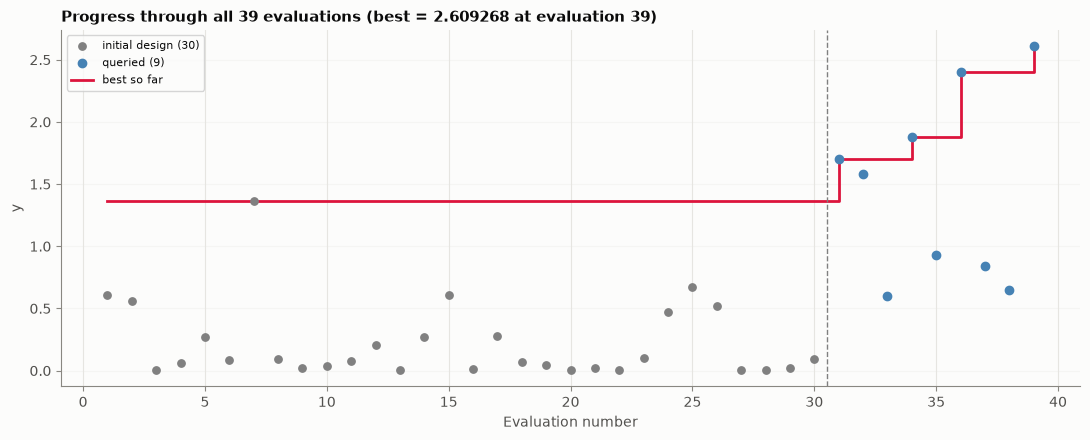

In [3]:
#--------------------------------------------------------------------------
# Optimisation history: Progress so far
#--------------------------------------------------------------------------
plt.figure(figsize=(11, 4.5))
best_idx=np.argmax(y)
evals = np.arange(1, n + 1)
running_best = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
plt.scatter(evals[:N_INITIAL], y[:N_INITIAL], color="gray", s=28, zorder=3, label=f"initial design ({N_INITIAL})")
plt.scatter(evals[N_INITIAL:], y[N_INITIAL:], color="steelblue", s=36, zorder=3, label=f"queried ({n - N_INITIAL})")
plt.step(evals, running_best, where="post", color="crimson", lw=2, zorder=2, label="best so far")
plt.axvline(N_INITIAL + 0.5, color="gray", ls="--", lw=1)
plt.xlabel("Evaluation number")
plt.ylabel("y")
plt.title(f"Progress through all {n} evaluations (best = {y.max():.6f} at evaluation {best_idx + 1})")
plt.grid(axis="y", alpha=0.3)
plt.legend(fontsize=8, loc="upper left")
plt.tight_layout()


Shapiro-Wilk normality test (p-value; higher = more Gaussian-like):
  raw y      : W=0.744, p=0.0000
  log(y)     : W=0.942, p=0.0445

log-transform is still valid.



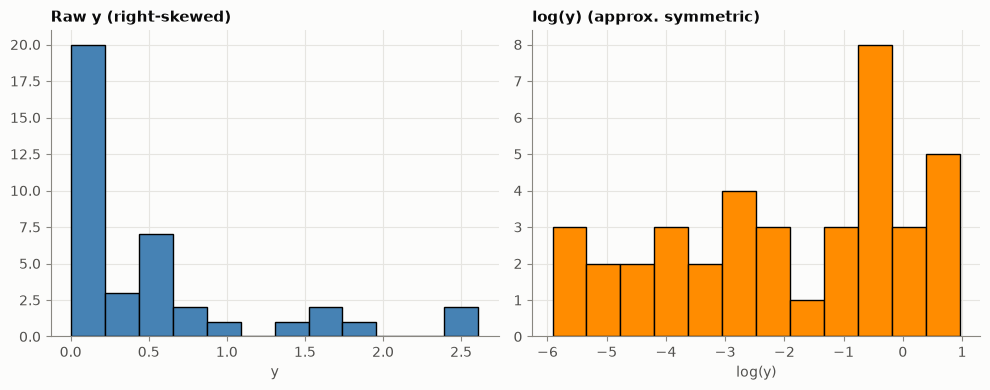

In [4]:
# -----------------------------------------------------------------------
# DATA TRANSFORMATION
# -----------------------------------------------------------------------
y_log = np.log(y)
sw_raw = shapiro(y)
sw_log = shapiro(y_log)
print(f"\nShapiro-Wilk normality test (p-value; higher = more Gaussian-like):")
print(f"  raw y      : W={sw_raw.statistic:.3f}, p={sw_raw.pvalue:.4f}")
print(f"  log(y)     : W={sw_log.statistic:.3f}, p={sw_log.pvalue:.4f}")
print("\nlog-transform is still valid.\n")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(y, bins=12, color="steelblue", edgecolor="k")
axes[0].set_title("Raw y (right-skewed)")
axes[0].set_xlabel("y")
axes[1].hist(y_log, bins=12, color="darkorange", edgecolor="k")
axes[1].set_title("log(y) (approx. symmetric)")
axes[1].set_xlabel("log(y)")
plt.tight_layout()


Refitted kernel (n=39):
  1.12**2 * Matern(length_scale=[1.66, 1.15, 0.857, 0.581, 0.506, 0.776], nu=2.5) + WhiteKernel(noise_level=1e-06)

Updated ARD length-scales per dimension (smaller = more influential):
  x0: 1.6614
  x1: 1.1531
  x2: 0.8567
  x3: 0.5805
  x4: 0.5062
  x5: 0.7759

Signal variance: 1.2651
Noise variance: 0.000001



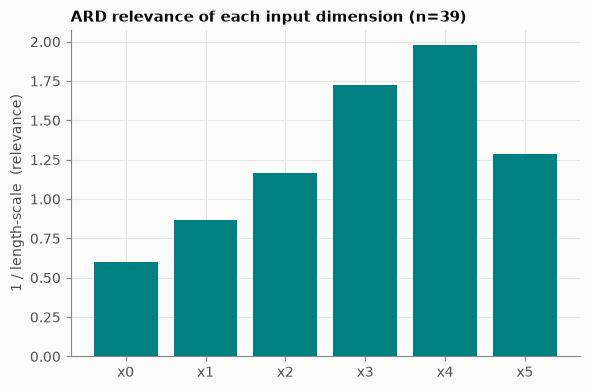

In [5]:
# -----------------------------------------------------------------------
# SURROGATE: Matern-5/2, ARD, + noise
# -----------------------------------------------------------------------
kernel = (
    ConstantKernel(1.0, (1e-2, 1e3))
    * Matern(length_scale=np.ones(d), length_scale_bounds=(1e-2, 1e2), nu=2.5)
    + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-6, 1.0))
)

gp = GaussianProcessRegressor(
    kernel=kernel,
    normalize_y=True,
    n_restarts_optimizer=25,
    random_state=SEED,
)
gp.fit(X, y_log)

print(f"\nRefitted kernel (n={n}):")
print(" ", gp.kernel_)

k1 = gp.kernel_.k1
ard_lengthscales = k1.k2.length_scale
signal_var = k1.k1.constant_value
noise_var = gp.kernel_.k2.noise_level
print("\nUpdated ARD length-scales per dimension (smaller = more influential):")
for i, ls in enumerate(ard_lengthscales):
    print(f"  x{i}: {ls:.4f}")
print(f"\nSignal variance: {signal_var:.4f}")
print(f"Noise variance: {noise_var:.6f}\n")
for i, ls in enumerate(ard_lengthscales):
    if np.isclose(ls, 1e-2, rtol=1e-3) or np.isclose(ls, 1e2, rtol=1e-3):
        print(f"  WARNING: x{i} length-scale ({ls:.4f}) is on an optimisation bound.\n")

plt.figure(figsize=(6, 4))
importance = 1.0 / ard_lengthscales
plt.bar([f"x{i}" for i in range(d)], importance, color="teal")
plt.ylabel("1 / length-scale  (relevance)")
plt.title(f"ARD relevance of each input dimension (n={n})")
plt.tight_layout()


Leave-one-out RMSE (log-space): 1.2417  (= 0.6201 of std(log y); 1.0 = no better than the mean)
LOO 95% CI empirical coverage: 0.82  (target 0.95)



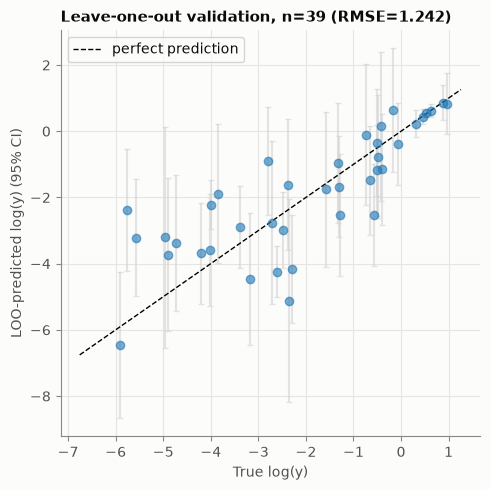

In [6]:
# -----------------------------------------------------------------------
# LOO cross-validation
# -----------------------------------------------------------------------
loo = LeaveOneOut()
preds, stds, trues = [], [], []
for train_idx, test_idx in loo.split(X):
    gp_cv = GaussianProcessRegressor(
        kernel=kernel, normalize_y=True, n_restarts_optimizer=5, random_state=SEED
    )
    gp_cv.fit(X[train_idx], y_log[train_idx])
    mu, sigma = gp_cv.predict(X[test_idx], return_std=True)
    preds.append(mu[0]); stds.append(sigma[0]); trues.append(y_log[test_idx][0])
preds, stds, trues = np.array(preds), np.array(stds), np.array(trues)
rmse = np.sqrt(np.mean((preds - trues) ** 2))
z = (trues - preds) / stds
coverage95 = np.mean(np.abs(z) <= 1.96)
print(f"\nLeave-one-out RMSE (log-space): {rmse:.4f}  "
      f"(= {rmse / y_log.std():.4f} of std(log y); 1.0 = no better than the mean)")
print(f"LOO 95% CI empirical coverage: {coverage95:.2f}  (target 0.95)\n")

plt.figure(figsize=(5, 5))
plt.errorbar(trues, preds, yerr=1.96 * stds, fmt="o", alpha=0.6, ecolor="lightgray", capsize=2)
lims = [min(trues.min(), preds.min()) - 0.3, max(trues.max(), preds.max()) + 0.3]
plt.plot(lims, lims, "k--", lw=1, label="perfect prediction")
plt.xlabel("True log(y)")
plt.ylabel("LOO-predicted log(y) (95% CI)")
plt.title(f"Leave-one-out validation, n={n} (RMSE={rmse:.3f})")
plt.legend()
plt.tight_layout()

In [7]:
# -----------------------------------------------------------------------
# ACQUISITION: EI, but with tighten xi
# -----------------------------------------------------------------------

def expected_improvement(Xq, gp, g_best, xi=0.005):
    Xq = np.atleast_2d(Xq)
    mu, sigma = gp.predict(Xq, return_std=True)
    sigma = np.maximum(sigma, 1e-9)
    imp = mu - g_best - xi
    Z = imp / sigma
    return imp * norm.cdf(Z) + sigma * norm.pdf(Z)

g_best = y_log.max()
best_idx = np.argmax(y_log)
print(f"\nIncumbent best (log-space): {g_best:.4f}  ->  y_best = {np.exp(g_best):.4f}")
print(f"Achieved at x = {X[best_idx]}  (row idx{best_idx})")

bounds = [(0.0, 1.0)] * d

def maximise(fn, n_restarts=20, n_sobol=2**14, seed=SEED):
    cands = np.vstack([qmc.Sobol(d, seed=seed).random(n_sobol), X])
    vals = fn(cands)
    order = np.argsort(-vals)[:n_restarts]
    bx, bv = cands[order[0]], vals[order[0]]
    for x0 in cands[order]:
        res = minimize(lambda x: -fn(x.reshape(1, -1))[0], x0, bounds=bounds, method="L-BFGS-B")
        if -res.fun > bv:
            bv, bx = -res.fun, res.x
    return bx, bv


best_x, best_ei = maximise(lambda Z: expected_improvement(Z, gp, g_best, xi=0.005))

mu_next, sigma_next = gp.predict(best_x.reshape(1, -1), return_std=True)
mean_y_next = np.exp(mu_next[0] + 0.5 * sigma_next[0] ** 2)
median_y_next = np.exp(mu_next[0])

print("\n" + "=" * 100)
print(f"NEXT QUERY POINT BY EI")
print("=" * 100)
print("x_next =", np.round(best_x, 6))
print(f"Expected Improvement value: {best_ei:.6f}")
print(f"GP posterior in log-space : mean={mu_next[0]:.4f}, std={sigma_next[0]:.4f}")
print(f"Predicted y (log-normal median) : {median_y_next:.4f}")
print(f"Predicted y (log-normal mean)   : {mean_y_next:.4f}")

d_incumbent = np.linalg.norm(best_x - X[best_idx])
print(f"Distance from the EI point to the current incumbent best: {d_incumbent:.3f}\n")


Incumbent best (log-space): 0.9591  ->  y_best = 2.6093
Achieved at x = [0.       0.145556 0.368993 0.327291 0.295019 0.596554]  (row idx38)

NEXT QUERY POINT BY EI
x_next = [0.       0.446317 0.505896 0.365926 0.318469 0.571062]
Expected Improvement value: 0.113070
GP posterior in log-space : mean=0.7913, std=0.4684
Predicted y (log-normal median) : 2.2063
Predicted y (log-normal mean)   : 2.4622
Distance from the EI point to the current incumbent best: 0.335



In [8]:
# -----------------------------------------------------------------------
# Exploitation candidate and sqrt(y) cross-check
# -----------------------------------------------------------------------

x_mean, mu_mean = maximise(lambda Z: gp.predict(Z))
_, sd_mean = gp.predict(x_mean.reshape(1, -1), return_std=True)

# Same kernel family on sqrt(y) -- a milder transform than log(y), which
# stretches the many near-zero values.
y_sqrt = np.sqrt(y)
gp_sqrt = GaussianProcessRegressor(kernel=kernel, normalize_y=True,
                                   n_restarts_optimizer=25, random_state=SEED).fit(X, y_sqrt)
x_sqrt, _ = maximise(lambda Z: expected_improvement(Z, gp_sqrt, y_sqrt.max(), xi=0.005))


def loo_fixed(gp_model, target):
    """Leave-one-out predictions with hyperparameters held at the full fit."""
    out = np.empty(n)
    for i_ in range(n):
        keep = np.arange(n) != i_
        g_ = GaussianProcessRegressor(kernel=gp_model.kernel_, optimizer=None,
                                      normalize_y=True).fit(X[keep], target[keep])
        out[i_] = g_.predict(X[i_:i_ + 1])[0]
    return out


loo_log, loo_sqrt = loo_fixed(gp, y_log), loo_fixed(gp_sqrt, y_sqrt)
print("\n" + "=" * 60)
print("CANDIDATES AND MODEL CROSS-CHECK")
print("=" * 60)
print("Leave-one-out (hyperparameters fixed), RMSE / std of own target and rank correlation with y:")
print(f"  log(y)  model: {np.sqrt(np.mean((y_log - loo_log) ** 2)) / y_log.std():.4f}   "
      f"Spearman = {spearmanr(y, loo_log)[0]:.4f}")
print(f"  sqrt(y) model: {np.sqrt(np.mean((y_sqrt - loo_sqrt) ** 2)) / y_sqrt.std():.4f}   "
      f"Spearman = {spearmanr(y, loo_sqrt)[0]:.4f}")

candidates = {"EI, log(y) model": best_x,
              "highest predicted mean, log(y)": x_mean,
              "EI, sqrt(y) model": x_sqrt,
              "incumbent (observed)": X[best_idx]}
print(f"\n  {'candidate':32s} {'x (6 d.p.)':58s} {'y_hat log':>10s} {'y_hat sqrt':>11s} {'dist':>6s}")
for name, xc in candidates.items():
    p_log = np.exp(gp.predict(xc.reshape(1, -1))[0])
    p_sqrt = gp_sqrt.predict(xc.reshape(1, -1))[0] ** 2
    x_str = "[" + ", ".join(f"{v:.6f}" for v in np.clip(xc, 0.0, 1.0)) + "]"
    print(f"  {name:32s} {x_str:58s} {p_log:10.4f} {p_sqrt:11.4f} "
          f"{np.linalg.norm(xc - X[best_idx]):6.3f}")
print("  y_hat = predicted median y under each model")
print("  dist = distance to the incumbent.)\n")




CANDIDATES AND MODEL CROSS-CHECK
Leave-one-out (hyperparameters fixed), RMSE / std of own target and rank correlation with y:
  log(y)  model: 0.4864   Spearman = 0.8838
  sqrt(y) model: 0.2977   Spearman = 0.9166

  candidate                        x (6 d.p.)                                                  y_hat log  y_hat sqrt   dist
  EI, log(y) model                 [0.000000, 0.446317, 0.505896, 0.365926, 0.318469, 0.571062]     2.2063      2.0144  0.335
  highest predicted mean, log(y)   [0.000000, 0.208883, 0.399928, 0.312161, 0.326241, 0.644055]     2.7183      2.7017  0.092
  EI, sqrt(y) model                [0.000000, 0.167913, 0.679927, 0.276861, 0.333284, 0.634382]     1.6867      2.8456  0.320
  incumbent (observed)             [0.000000, 0.145556, 0.368993, 0.327291, 0.295019, 0.596554]     2.6093      2.6093  0.000
  y_hat = predicted median y under each model
  dist = distance to the incumbent.)



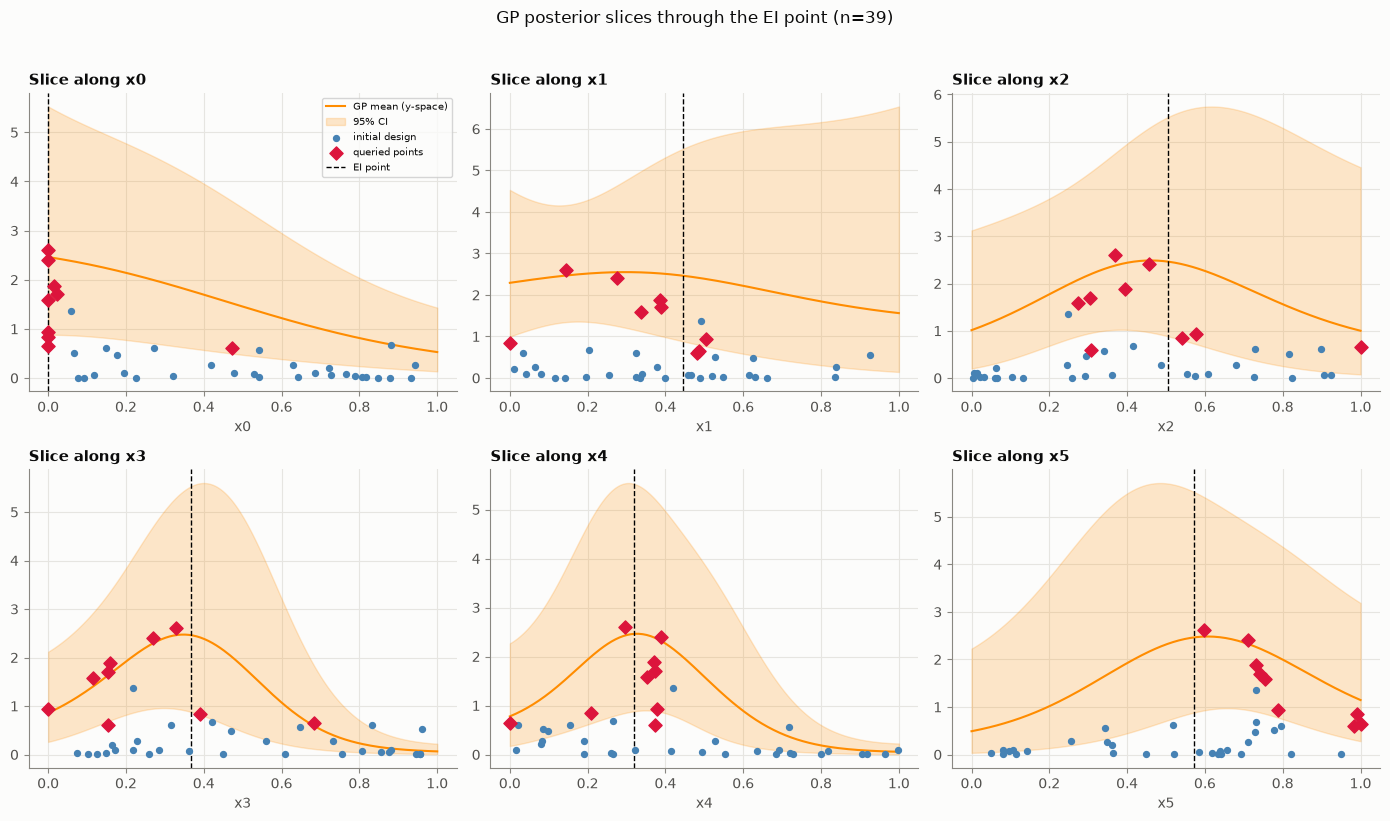

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
grid = np.linspace(0, 1, 200)
for i, ax in enumerate(axes.flat):
    Xs = np.tile(best_x, (200, 1))
    Xs[:, i] = grid
    mu_s, sigma_s = gp.predict(Xs, return_std=True)
    y_mu = np.exp(mu_s + 0.5 * sigma_s ** 2)
    y_lo = np.exp(mu_s - 1.96 * sigma_s)
    y_hi = np.exp(mu_s + 1.96 * sigma_s)
    ax.plot(grid, y_mu, color="darkorange", label="GP mean (y-space)")
    ax.fill_between(grid, y_lo, y_hi, color="darkorange", alpha=0.2, label="95% CI")
    ax.scatter(X[:N_INITIAL, i], y[:N_INITIAL], color="steelblue", s=18, zorder=5, label="initial design")
    ax.scatter(X[N_INITIAL:, i], y[N_INITIAL:], color="crimson", s=45, marker="D", zorder=6, label="queried points")
    ax.axvline(best_x[i], color="k", ls="--", lw=1, label="EI point")
    ax.set_title(f"Slice along x{i}")
    ax.set_xlabel(f"x{i}")
    if i == 0:
        ax.legend(fontsize=7)
plt.suptitle(f"GP posterior slices through the EI point (n={n})", y=1.02)
plt.tight_layout()